In [115]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

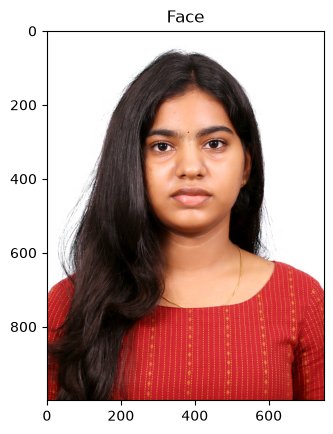

In [116]:
# Load the Face Image
faceImage = cv2.imread('NEHA IMAGE.jpeg')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [117]:
faceImage.shape

(1000, 750, 3)

In [118]:
#resized_faceImage.shape
faceImage.shape

(1000, 750, 3)

Text(0.5, 1.0, 'glassPNG')

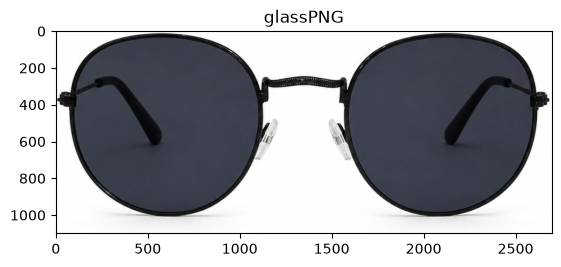

In [119]:
# Load the Sunglass image
glassPNG = cv2.imread(r"C:\Users\acer\Downloads\sun.jpg")
plt.imshow(cv2.cvtColor(glassPNG, cv2.COLOR_BGR2RGB))
plt.title("glassPNG")

In [120]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG, (300, 110))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(110, 300, 3)


In [121]:
# Resize sunglasses
glassBGR = cv2.resize(glassBGR, (300, 110))

# Convert sunglasses to grayscale
glassGray = cv2.cvtColor(glassBGR, cv2.COLOR_BGR2GRAY)

# Create mask to remove white background
_, glassMask1 = cv2.threshold(glassGray, 240, 255, cv2.THRESH_BINARY_INV)

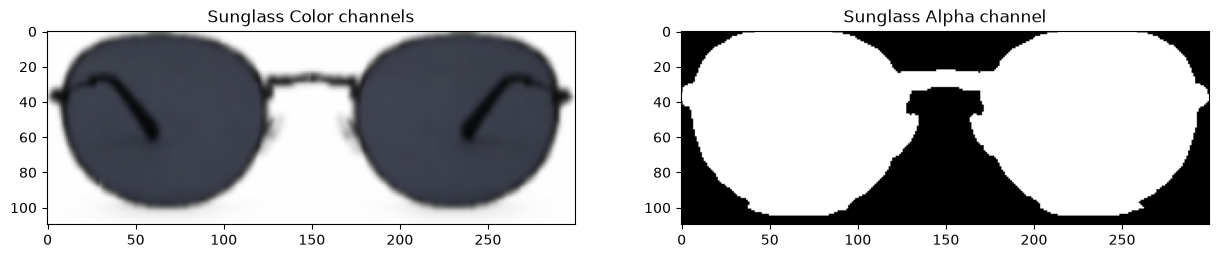

In [122]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

(np.float64(-0.5), np.float64(749.5), np.float64(999.5), np.float64(-0.5))

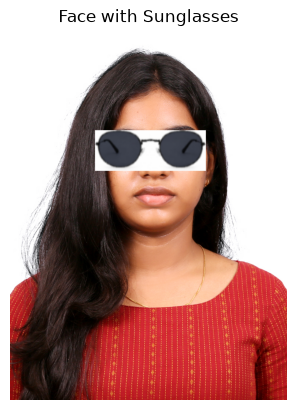

In [123]:
# Make a copy
faceWithGlassesNaive = faceImage.copy()

# Replace the eye region with the sunglass image
faceWithGlassesNaive[270:380, 230:530] = glassBGR

# Display the result
plt.imshow(faceWithGlassesNaive[..., ::-1])
plt.title("Face with Sunglasses")
plt.axis('off')

Text(0.5, 1.0, 'Augmented Eye and Sunglass')

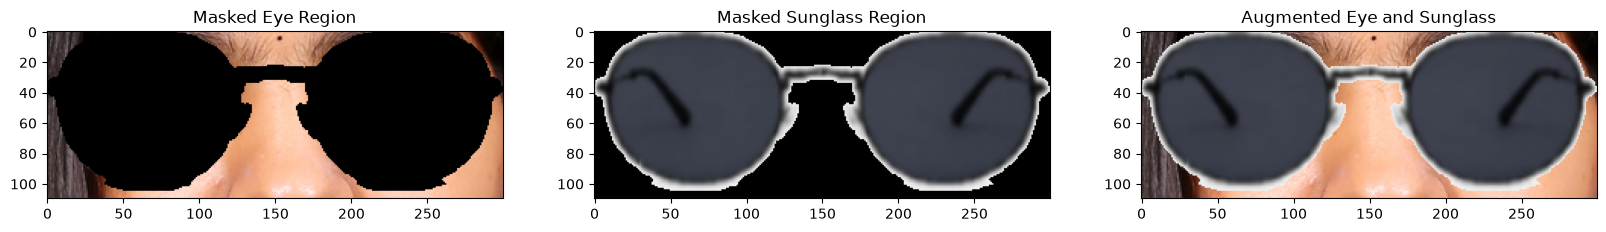

In [124]:
# Make the dimensions of the mask same as the input image
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))

# Make the values [0,1]
glassMask = np.uint8(glassMask / 255)

# Make a copy
faceWithGlassesArithmetic = faceImage.copy()

# Get the eye region from the face image
eyeROI = faceWithGlassesArithmetic[270:380, 230:530]

# Use the mask to create the masked eye region
maskedEye = cv2.multiply(eyeROI, (1 - glassMask))

# Use the mask to create the masked sunglass region
maskedGlass = cv2.multiply(glassBGR, glassMask)

# Combine the sunglasses in the eye region
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Display the intermediate results
plt.figure(figsize=(20,20))
plt.subplot(131);plt.imshow(maskedEye[...,::-1]);plt.title("Masked Eye Region")
plt.subplot(132);plt.imshow(maskedGlass[...,::-1]);plt.title("Masked Sunglass Region")
plt.subplot(133);plt.imshow(eyeRoiFinal[...,::-1]);plt.title("Augmented Eye and Sunglass")

Text(0.5, 1.0, 'With Sunglasses')

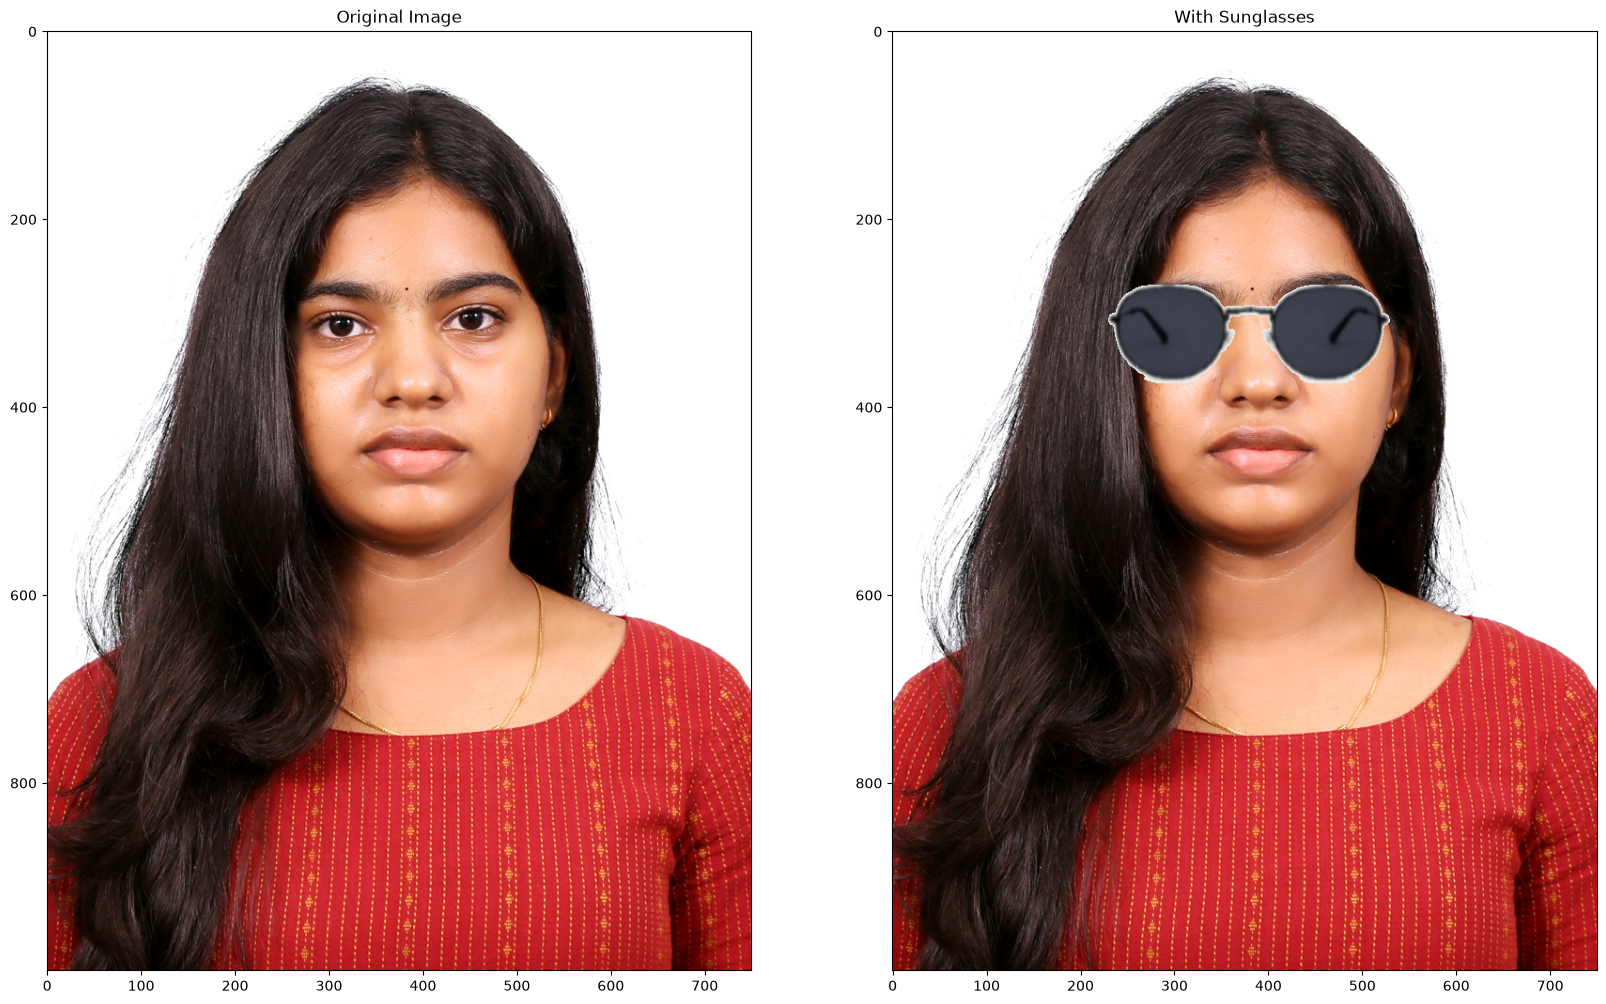

In [125]:
# Resize sunglasses to fit both eyes
glassBGR = cv2.resize(glassBGR, (300, 110))

# Create a mask to remove the white background
grayGlass = cv2.cvtColor(glassBGR, cv2.COLOR_BGR2GRAY)

glassMask1 = cv2.threshold(
    grayGlass, 240, 255, cv2.THRESH_BINARY_INV
)[1]

# Convert mask into 3 channels
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))

# Convert values into 0 and 1
glassMask = np.uint8(glassMask / 255)

# Make a copy
faceWithGlassesArithmetic = faceImage.copy()

# Get the eye region
eyeROI = faceWithGlassesArithmetic[270:380, 230:530]

# Apply mask
maskedEye = cv2.multiply(eyeROI, (1 - glassMask))

# Apply sunglasses mask
maskedGlass = cv2.multiply(glassBGR, glassMask)

# Combine both regions
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Replace the eye region
faceWithGlassesArithmetic[270:380, 230:530] = eyeRoiFinal

# Display results
plt.figure(figsize=(20,20))
plt.subplot(121);plt.imshow(faceImage[:,:,::-1]);plt.title("Original Image")
plt.subplot(122);plt.imshow(faceWithGlassesArithmetic[:,:,::-1]);plt.title("With Sunglasses")